# SensIA Rede Neural com GridSearch no VS Code

**Abra esta pasta no VS Code, selecione o kernel Python da sua .venv e execute de cima para baixo.** Coloque os três CSVs de embeddings na subpasta `Embeddings`. 

Treinamos somente o classificador de temas, mantendo o BGE-M3 congelado.

Vamos comparar uma camada oculta com **32, 64 e 128 neurônios**. A rede de 128 permanece como referência, sem pressupor que uma rede menor será melhor. GridSearchCV testa todas as combinações e escolhe pelo **F1 macro da validação**, que dá o mesmo peso às nove classes [1].

| Parâmetro | Valores | Motivo |
|---|---|---|
| Neurônios | 32, 64, 128 | Investigar menor complexidade |
| alpha | 0.001, 0.01, 0.1 | Comparar penalização L2 dos pesos |
| Épocas | 10, 20 | Comparar dois orçamentos próximos ao início do sobreajuste observado |

São **18 combinações**. Mantemos ReLU, Adam, batch 64 e taxa de aprendizado 0.001 para limitar o experimento. Não há garantia de melhora. A complexidade cai de 132.361 parâmetros em 128 neurônios para 66.185 em 64 e 33.097 em 32.

**PredefinedSplit preserva treino e validação existentes**: `-1` identifica treino e `0` identifica validação. É uma única divisão fixa, não validação cruzada com vários folds [2]. O teste não entra na busca. Usamos `refit=False` para impedir o reajuste automático com treino + validação; depois treinamos a configuração vencedora apenas no treino.

Nesta versão, o número de épocas também é escolhido pela grade.

### Preparação do ambiente

Instale as dependências pelo terminal seguindo `LEIA_PRIMEIRO.md`. O notebook usa o ambiente local selecionado em **Select Kernel**. Se aparecer `ModuleNotFoundError`, confira se selecionou a mesma `.venv` onde instalou os pacotes.


In [1]:
from pathlib import Path
from datetime import datetime
import json, hashlib, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, PredefinedSplit, ParameterGrid
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from threadpoolctl import threadpool_limits

# Abra a pasta SensIA_VSCode no VS Code antes de executar.
PASTA = Path.cwd() / 'Embeddings'
# Se necessário, use um caminho completo, por exemplo:
# PASTA = Path(r'C:\Users\SeuUsuario\Downloads\SensIA_VSCode\Embeddings')
print('Pasta dos embeddings:', PASTA.resolve())
ENTRADA = 'descricao'
SEED = 42
SAIDA = PASTA.parent / 'resultados_gridsearch' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
SAIDA.mkdir(parents=True, exist_ok=False)

Pasta dos embeddings: C:\Users\anabe\OneDrive\Documentos\SENSIA_RES\SensIA\SensIA_VSCode\Embeddings


### 1 Carregar e conferir a integridade

Reutilizamos as verificações de IDs, descrições, classes e vetores. A leitura do teste aqui verifica apenas integridade; seus resultados não participam da seleção. Isso não substitui revisão de rótulos ou análise de similaridade entre vídeos/canais.

In [2]:
if ENTRADA not in ('descricao', 'transcricao'):
    raise ValueError("ENTRADA deve ser 'descricao' ou 'transcricao'.")
coluna_texto = 'descricao_global' if ENTRADA == 'descricao' else 'transcricao_pronta'
colunas = [f'embedding_{i}' for i in range(1, 1025)]
dados = {}
for split in ('treino', 'validacao', 'teste'):
    arquivo = PASTA / f'embeddings_{split}_{ENTRADA}.csv'
    if not arquivo.exists():
        raise FileNotFoundError(f'Arquivo não encontrado: {arquivo}. Confira o caminho e o salvamento dos embeddings.')
    df = pd.read_csv(arquivo, dtype={'video_id': str, 'categoria': str})
    faltam = set(colunas + ['video_id', 'categoria', 'split', coluna_texto]) - set(df.columns)
    if faltam:
        raise ValueError(f'{split}: colunas ausentes: {sorted(faltam)[:8]}')
    if len(df) == 0 or df[['video_id', 'categoria', coluna_texto]].isna().any().any():
        raise ValueError(f'{split}: conjunto vazio ou ID, classe ou texto ausentes.')
    for c in ('video_id', 'categoria', coluna_texto):
        if df[c].str.strip().eq('').any():
            raise ValueError(f'{split}: campo vazio em {c}.')
    if df.video_id.duplicated().any() or not df['split'].eq(split).all():
        raise ValueError(f'{split}: vídeo duplicado ou coluna split inconsistente.')
    vetores = df[colunas].to_numpy(dtype=np.float32)
    if not np.isfinite(vetores).all() or (np.linalg.norm(vetores, axis=1) == 0).any():
        raise ValueError(f'{split}: embeddings inválidos ou vetores nulos.')
    dados[split] = df

classes = np.sort(dados['treino'].categoria.unique())
if len(classes) != 9:
    raise ValueError(f'Esperadas nove classes; encontradas {len(classes)}.')
for split, df in dados.items():
    if set(df.categoria) != set(classes):
        raise ValueError(f'{split}: precisa conter exemplos de todas as nove classes para esta avaliação.')
for a, b in [('treino', 'validacao'), ('treino', 'teste'), ('validacao', 'teste')]:
    ids_comuns = set(dados[a].video_id) & set(dados[b].video_id)
    textos_a = set(dados[a][coluna_texto].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip())
    textos_b = set(dados[b][coluna_texto].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip())
    if ids_comuns or textos_a & textos_b:
        raise ValueError(f'Sobreposição entre {a} e {b}. Revise os splits antes de treinar; não exclua linhas silenciosamente.')

print('Integridade básica OK. Embeddings por exemplo:', len(colunas))
display(pd.DataFrame({s: df.categoria.value_counts() for s, df in dados.items()}).loc[classes])

Integridade básica OK. Embeddings por exemplo: 1024


,treino,validacao,teste
categoria,,,
Art & Creativity,346,78,76
Automotive,362,60,78
Education,352,74,74
Entertainment,346,72,82
Hobbies & Interests,345,79,76
Lifestyle,357,72,71
News & Politics,339,77,84
Science & Technology,357,72,71
Sports,355,73,72


### 2 Executar o GridSearch

`tol=0` e `n_iter_no_change=21` mantêm os orçamentos de 10 ou 20 épocas. 

O pipeline aplica normalização L2 por vetor, como no experimento inicial. `n_jobs=1` e até duas threads numéricas limitam o uso de memória/CPU no computador. A busca é mais demorada que um único treino; `verbose=2` mostra cada configuração concluída. Não é necessário GPU nem carregar o BGE-M3 novamente.

In [3]:
X_treino = dados['treino'][colunas].to_numpy(dtype=np.float32)
X_validacao = dados['validacao'][colunas].to_numpy(dtype=np.float32)
y_treino = dados['treino'].categoria.to_numpy()
y_validacao = dados['validacao'].categoria.to_numpy()

X_busca = np.concatenate([X_treino, X_validacao])
y_busca = np.concatenate([y_treino, y_validacao])
particao = PredefinedSplit(np.r_[np.full(len(y_treino), -1), np.zeros(len(y_validacao), dtype=int)])
pipeline = Pipeline([
    ('normalizar', Normalizer(norm='l2')),
    ('mlp', MLPClassifier(activation='relu', solver='adam', learning_rate_init=0.001,
        batch_size=min(64, len(y_treino)), early_stopping=False, tol=0.0,
        n_iter_no_change=21, shuffle=True, random_state=SEED))
])
grade = {
    'mlp__hidden_layer_sizes': [(32,), (64,), (128,)],
    'mlp__alpha': [0.001, 0.01, 0.1],
    'mlp__max_iter': [10, 20]
}
busca_grid = GridSearchCV(pipeline, grade, scoring='f1_macro', cv=particao,
    refit=False, return_train_score=True, n_jobs=1, verbose=2, error_score='raise')
print('Combinações a avaliar:', len(list(ParameterGrid(grade))))
with warnings.catch_warnings(), threadpool_limits(limits=2):
    warnings.simplefilter('ignore', ConvergenceWarning)
    busca_grid.fit(X_busca, y_busca)

resultados_grid = pd.DataFrame(busca_grid.cv_results_)
comparacao = pd.DataFrame({
    'neuronios': resultados_grid.param_mlp__hidden_layer_sizes.map(lambda x: x[0]),
    'alpha': resultados_grid.param_mlp__alpha.astype(float),
    'epocas': resultados_grid.param_mlp__max_iter.astype(int),
    'f1_treino': resultados_grid.mean_train_score,
    'f1_validacao': resultados_grid.mean_test_score,
    'segundos_treino': resultados_grid.mean_fit_time
})
# mean_test_score é o nome da API; aqui representa a VALIDAÇÃO, não teste.csv.
comparacao['diferenca_treino_validacao'] = comparacao.f1_treino - comparacao.f1_validacao
comparacao = comparacao.sort_values('f1_validacao', ascending=False)
display(comparacao.round(4))
melhores_parametros = busca_grid.best_params_
print('Configuração selecionada:', melhores_parametros)
print('Melhor F1 macro na validação:', round(busca_grid.best_score_, 4))
comparacao.to_csv(SAIDA / 'comparacao_gridsearch.csv', index=False)

Combinações a avaliar: 18
Fitting 1 folds for each of 18 candidates, totalling 18 fits
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(32,), mlp__max_iter=10; total time=   1.0s
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(32,), mlp__max_iter=20; total time=   1.8s
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(64,), mlp__max_iter=10; total time=   1.5s
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(64,), mlp__max_iter=20; total time=   1.9s
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(128,), mlp__max_iter=10; total time=   2.1s
[CV] END mlp__alpha=0.001, mlp__hidden_layer_sizes=(128,), mlp__max_iter=20; total time=   4.9s
[CV] END mlp__alpha=0.01, mlp__hidden_layer_sizes=(32,), mlp__max_iter=10; total time=   0.6s
[CV] END mlp__alpha=0.01, mlp__hidden_layer_sizes=(32,), mlp__max_iter=20; total time=   1.3s
[CV] END mlp__alpha=0.01, mlp__hidden_layer_sizes=(64,), mlp__max_iter=10; total time=   0.9s
[CV] END mlp__alpha=0.01, mlp__hidden_layer_sizes=(64,), ml

,neuronios,alpha,epocas,f1_treino,f1_validacao,segundos_treino,diferenca_treino_validacao
17,128,0.100,20,0.7640,0.6508,5.0222,0.1132
7,32,0.010,20,0.7538,0.6493,1.3955,0.1045
15,64,0.100,20,0.7423,0.6467,2.6276,0.0956
1,32,0.001,20,0.7598,0.6456,1.9167,0.1142
10,128,0.010,10,0.7422,0.6429,2.2214,0.0993
9,64,0.010,20,0.7813,0.6420,2.1626,0.1393
4,128,0.001,10,0.7458,0.6402,2.1888,0.1056
3,64,0.001,20,0.7826,0.6399,2.0218,0.1426
2,64,0.001,10,0.7292,0.6378,1.5595,0.0915
5,128,0.001,20,0.8169,0.6357,4.9487,0.1812


Configuração selecionada: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (128,), 'mlp__max_iter': 20}
Melhor F1 macro na validação: 0.6508


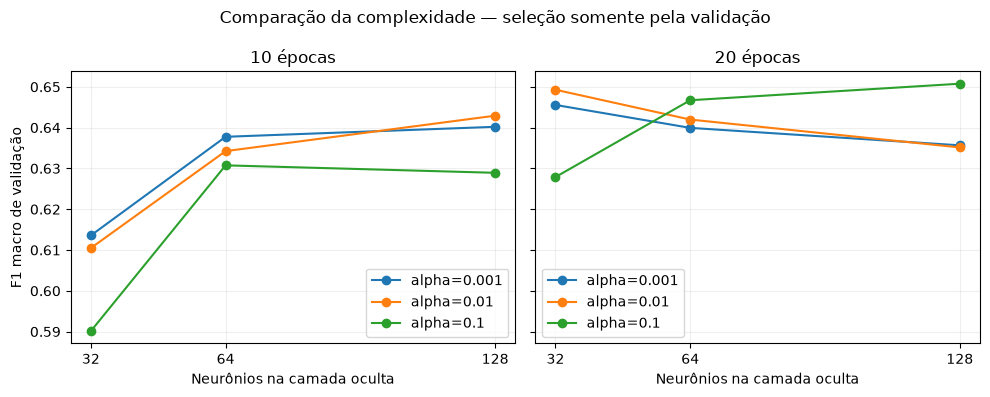

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, epocas in zip(eixos, [10, 20]):
    for alpha in grade['mlp__alpha']:
        pontos = comparacao[(comparacao.epocas == epocas) & (comparacao.alpha == alpha)].sort_values('neuronios')
        ax.plot(pontos.neuronios, pontos.f1_validacao, marker='o', label=f'alpha={alpha}')
    ax.set(title=f'{epocas} épocas', xlabel='Neurônios na camada oculta', xticks=[32, 64, 128])
    ax.grid(alpha=0.2); ax.legend()
eixos[0].set_ylabel('F1 macro de validação')
fig.suptitle('Comparação da complexidade — seleção somente pela validação')
fig.tight_layout()
fig.savefig(SAIDA / 'comparacao_complexidade.png', dpi=160, bbox_inches='tight')
plt.show()

### 3 Treinar a configuração selecionada

Treinamos novamente apenas com `treino.csv`, usando os parâmetros escolhidos. A semente fixa permite verificar se o F1 de validação é reproduzido. A curva abaixo mostra somente a perda interna de treino do modelo selecionado, incluindo regularização; ela não é uma curva de validação. A comparação entre configurações está no gráfico anterior.

Se a rede de 128 vencer, a grade não encontrou ganho ao reduzir a camada dentre estes candidatos. Se uma menor vencer, a seleção combina desempenho de validação e menor número de parâmetros. Não conclua superioridade geral a partir de uma divisão e uma semente.

F1 macro de validação: 0.6508
Neurônios: (128,) | Épocas executadas: 20
Parâmetros treináveis: 132361


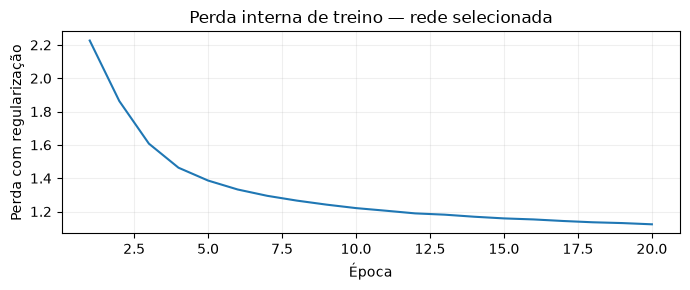

In [5]:
modelo_final = Pipeline(pipeline.steps).set_params(**melhores_parametros)
with warnings.catch_warnings(), threadpool_limits(limits=2):
    warnings.simplefilter('ignore', ConvergenceWarning)
    modelo_final.fit(X_treino, y_treino)
rede_final = modelo_final.named_steps['mlp']
f1_validacao = f1_score(y_validacao, modelo_final.predict(X_validacao), average='macro')
assert np.isclose(f1_validacao, busca_grid.best_score_), 'Treino final não reproduziu a seleção; confira a execução.'
numero_parametros = sum(p.size for p in rede_final.coefs_) + sum(p.size for p in rede_final.intercepts_)
print('F1 macro de validação:', round(f1_validacao, 4))
print('Neurônios:', rede_final.hidden_layer_sizes, '| Épocas executadas:', rede_final.n_iter_)
print('Parâmetros treináveis:', numero_parametros)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(rede_final.loss_curve_) + 1), rede_final.loss_curve_)
ax.set(title='Perda interna de treino — rede selecionada', xlabel='Época', ylabel='Perda com regularização')
ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(SAIDA / 'perda_treino.png', dpi=160, bbox_inches='tight')
plt.show()

### 4 Avaliação final no teste

Execute depois de fixar os parâmetros. Reportamos acurácia, F1 macro, relatório por classe e ROC-AUC macro OvR. A referência prevê a classe mais frequente do treino. Não use o teste para escolher entre as 18 configurações.

Este mesmo conjunto já foi consultado em experimentos anteriores: os resultados são uma avaliação de desenvolvimento, não um teste final nunca observado. A integração com descrições geradas de vídeos reais ainda precisa de avaliação própria.

In [6]:
X_teste = dados['teste'][colunas].to_numpy(dtype=np.float32)
y_teste = dados['teste'].categoria.to_numpy()
probabilidades = modelo_final.predict_proba(X_teste)
classes_modelo = rede_final.classes_  # ordem exata das colunas de predict_proba
previsoes = classes_modelo[probabilidades.argmax(axis=1)]

baseline = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
previsoes_base = baseline.predict(X_teste)
auc_macro = roc_auc_score(y_teste, probabilidades, labels=classes_modelo, multi_class='ovr', average='macro')
resumo = pd.DataFrame([
    {'modelo': 'Classe mais frequente', 'acuracia': accuracy_score(y_teste, previsoes_base),
     'f1_macro': f1_score(y_teste, previsoes_base, average='macro', zero_division=0), 'roc_auc_macro_ovr': np.nan},
    {'modelo': 'MLP GridSearch BGE-M3', 'acuracia': accuracy_score(y_teste, previsoes),
     'f1_macro': f1_score(y_teste, previsoes, average='macro', zero_division=0), 'roc_auc_macro_ovr': auc_macro}
])
relatorio = pd.DataFrame(classification_report(y_teste, previsoes, labels=classes_modelo,
                         output_dict=True, zero_division=0)).T
print('Resultados reais desta execução no conjunto de teste:')
display(resumo.round(4))
display(relatorio.round(4))

Resultados reais desta execução no conjunto de teste:


,modelo,acuracia,f1_macro,roc_auc_macro_ovr
0,Classe mais frequente,0.1140,0.0227,NaN
1,MLP GridSearch BGE-M3,0.6111,0.6049,0.9179


,precision,recall,f1-score,support
Art & Creativity,0.7353,0.6579,0.6944,76.0000
Automotive,0.7159,0.8077,0.7590,78.0000
Education,0.4328,0.3919,0.4113,74.0000
Entertainment,0.4627,0.3780,0.4161,82.0000
Hobbies & Interests,0.5075,0.4474,0.4755,76.0000
Lifestyle,0.5211,0.5211,0.5211,71.0000
News & Politics,0.6500,0.7738,0.7065,84.0000
Science & Technology,0.7467,0.7887,0.7671,71.0000
Sports,0.6543,0.7361,0.6928,72.0000
accuracy,0.6111,0.6111,0.6111,0.6111


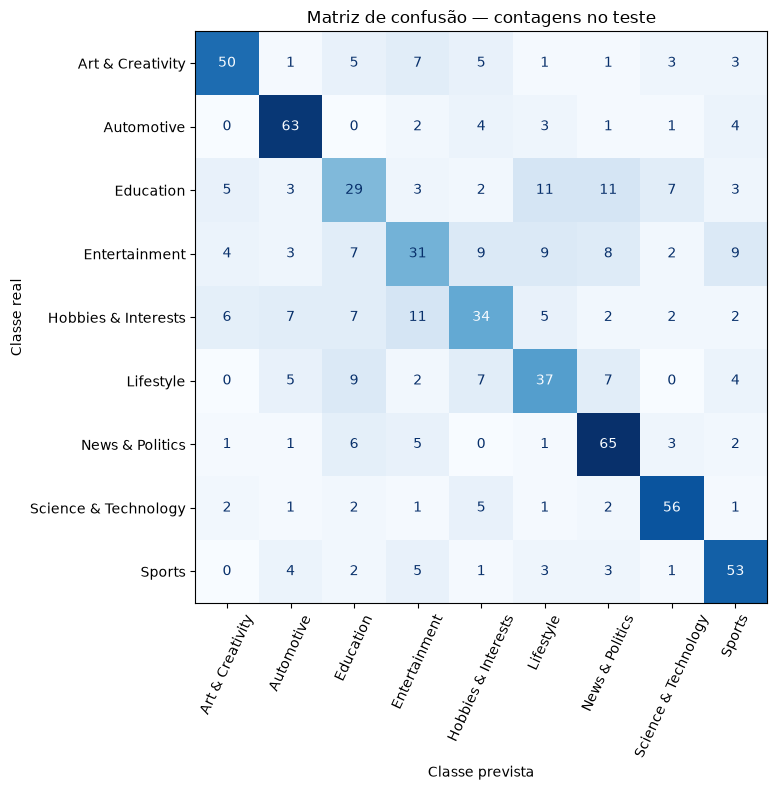

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_teste, previsoes, labels=classes_modelo,
    display_labels=classes_modelo, cmap='Blues', colorbar=False, ax=ax, xticks_rotation=65)
ax.set(title='Matriz de confusão — contagens no teste', xlabel='Classe prevista', ylabel='Classe real')
fig.tight_layout()
fig.savefig(SAIDA / 'matriz_confusao.png', dpi=160, bbox_inches='tight')
plt.show()

### 5 ROC-AUC separada para cada classe

Exibimos **nove painéis**, cada um comparando uma classe com todas as outras (One versus Rest). Usamos a coluna de probabilidades correspondente à ordem `classes_`, não rótulos previstos [4]. Também salvamos cada curva em um PNG próprio.

Quanto mais perto do canto superior esquerdo, melhor a separação. AUC não é acurácia e não comprova que as probabilidades sejam calibradas. A média macro dá o mesmo peso a cada classe. Leia junto de F1, recall e matriz de confusão.

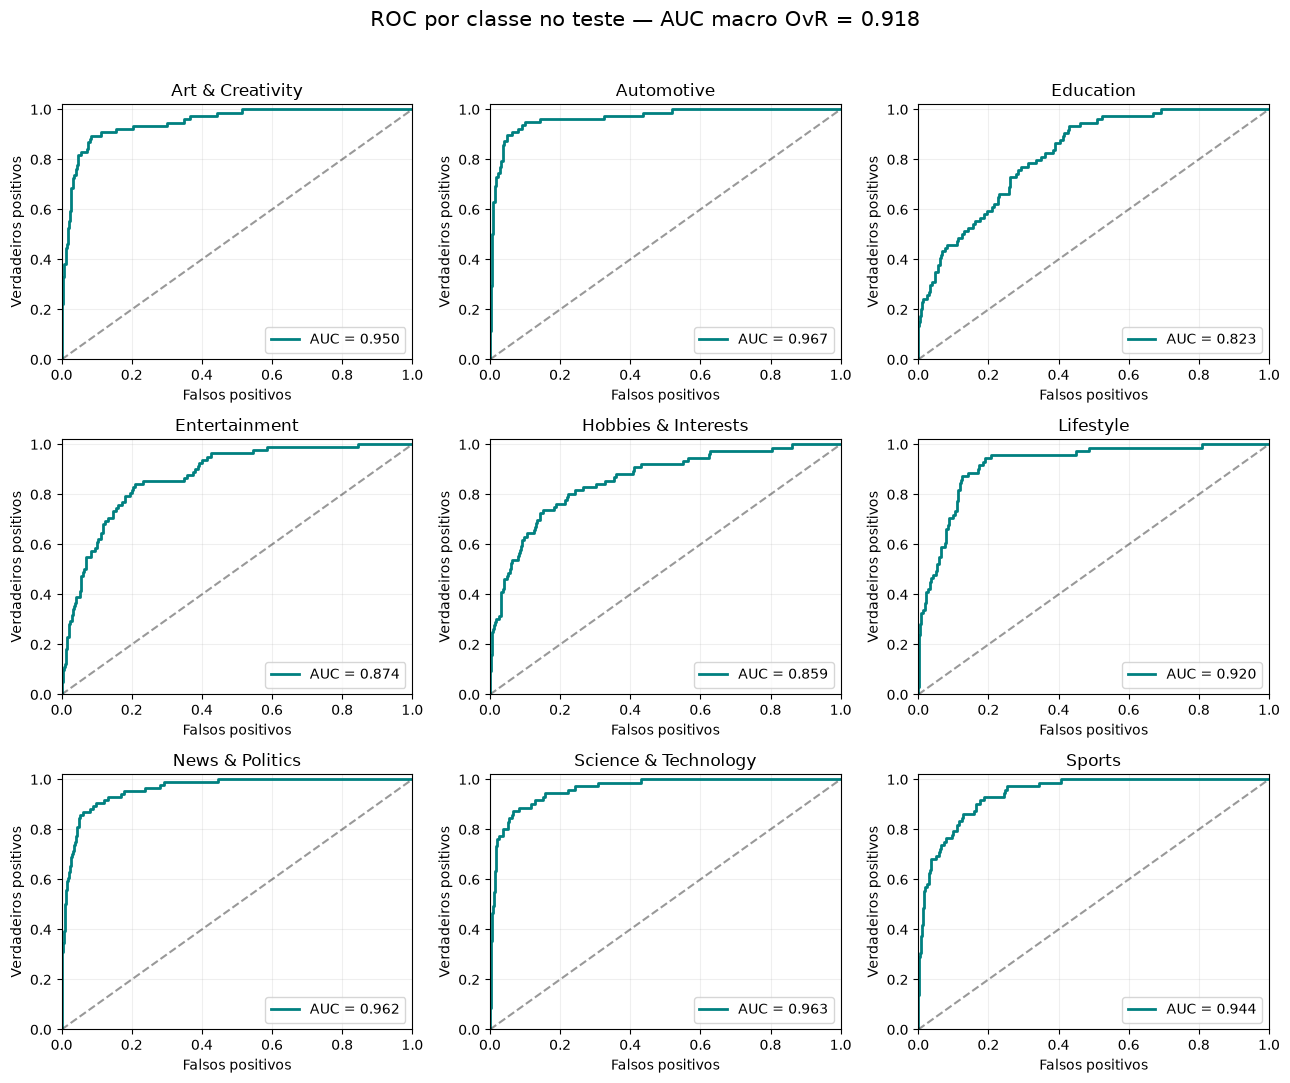

,classe,auc_ovr,exemplos_teste
0,Art & Creativity,0.9496,76
1,Automotive,0.9672,78
2,Education,0.8226,74
3,Entertainment,0.8735,82
4,Hobbies & Interests,0.8594,76
5,Lifestyle,0.9202,71
6,News & Politics,0.9619,84
7,Science & Technology,0.9630,71
8,Sports,0.9438,72


In [8]:
fig, eixos = plt.subplots(3, 3, figsize=(13, 11))
aucs = []
for i, (classe, ax) in enumerate(zip(classes_modelo, eixos.flat)):
    y_binario = (y_teste == classe).astype(int)
    fpr, tpr, _ = roc_curve(y_binario, probabilidades[:, i])
    auc_classe = roc_auc_score(y_binario, probabilidades[:, i])
    aucs.append({'classe': classe, 'auc_ovr': auc_classe, 'exemplos_teste': int(y_binario.sum())})
    ax.plot(fpr, tpr, color='teal', linewidth=2, label=f'AUC = {auc_classe:.3f}')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax.set(title=classe, xlabel='Falsos positivos', ylabel='Verdadeiros positivos',
           xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc='lower right'); ax.grid(alpha=0.2)
    # Exporta também uma figura individual por classe.
    fig_ind, ax_ind = plt.subplots(figsize=(5, 4))
    ax_ind.plot(fpr, tpr, color='teal', label=f'AUC = {auc_classe:.3f}')
    ax_ind.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax_ind.set(title=f'ROC — {classe}', xlabel='Falsos positivos', ylabel='Verdadeiros positivos',
               xlim=(0, 1), ylim=(0, 1.02))
    ax_ind.legend(); ax_ind.grid(alpha=0.2); fig_ind.tight_layout()
    fig_ind.savefig(SAIDA / f'roc_classe_{i+1:02d}.png', dpi=160, bbox_inches='tight')
    plt.close(fig_ind)
fig.suptitle(f'ROC por classe no teste — AUC macro OvR = {auc_macro:.3f}', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(SAIDA / 'roc_nove_classes.png', dpi=160, bbox_inches='tight')
plt.show()
aucs = pd.DataFrame(aucs)
display(aucs.round(4))

### 6 Salvar o modelo e os resultados

A pasta desta execução terá a grade completa, os parâmetros selecionados, o pipeline com normalização e rede, métricas, previsões, matriz de confusão, nove ROC individuais e o painel conjunto. Mantemos as configurações de extração BGE-M3 da origem; os embeddings não são recalculados aqui.

In [ ]:
joblib.dump(modelo_final, SAIDA / 'modelo_mlp_gridsearch.joblib')
pd.DataFrame({'epoca': range(1, len(rede_final.loss_curve_) + 1),
              'perda_treino': rede_final.loss_curve_}).to_csv(SAIDA / 'historico_treino.csv', index=False)
resumo.to_csv(SAIDA / 'metricas_teste.csv', index=False)
relatorio.to_csv(SAIDA / 'relatorio_classes.csv', encoding='utf-8-sig')
aucs.to_csv(SAIDA / 'auc_por_classe.csv', index=False)
previsoes_df = dados['teste'][['video_id', 'categoria']].copy()
previsoes_df['classe_prevista'] = previsoes
for i, classe in enumerate(classes_modelo):
    previsoes_df[f'probabilidade_{classe}'] = probabilidades[:, i]
previsoes_df.to_csv(SAIDA / 'previsoes_teste.csv', index=False, encoding='utf-8-sig')
config = {
    'encoder': 'BAAI/bge-m3', 'entrada': ENTRADA, 'dimensoes': 1024,
    'extracao_origem': {'max_length': 8192, 'use_fp16': False, 'return_dense': True},
    'classes': classes_modelo.tolist(), 'colunas': colunas, 'seed': SEED,
    'grade': grade, 'melhores_parametros': melhores_parametros,
    'f1_validacao': f1_validacao, 'numero_parametros': numero_parametros,
    'parametros_rede': rede_final.get_params(),
    'validacao': 'PredefinedSplit com um fold fixo; seleção por F1 macro; refit=False',
    'quantidades': {s: len(df) for s, df in dados.items()},
    'sha256_arquivos': {s: hashlib.sha256((PASTA / f'embeddings_{s}_{ENTRADA}.csv').read_bytes()).hexdigest() for s in dados},
    'versoes': {p: importlib.metadata.version(p) for p in ['scikit-learn','numpy','pandas','matplotlib','joblib']}
}
(SAIDA / 'configuracao.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Arquivos salvos em:', SAIDA)

Arquivos salvos em: c:\Users\anabe\OneDrive\Documentos\SENSIA_RES\SensIA\SensIA_VSCode\resultados_gridsearch\20261109_142601_937980


### Referências e interpretação

1. [GridSearchCV — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): busca exaustiva, scoring e controle do refit.
2. [PredefinedSplit — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.PredefinedSplit.html): divisão fixa de treino e validação com índices -1/0.
3. [MLPClassifier — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html): camada oculta, regularização L2, Adam e max_iter.
4. [ROC multiclasse — scikit-learn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html): curvas por classe com One versus Rest.
5. [Normalizer — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Normalizer.html): normalização L2 por exemplo.
6. [Boas práticas — scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html): processamento e separação dos dados.

Consultadas em 9 de novembro de 2026. Os valores da grade são escolhas do projeto; a documentação sustenta o método, não garante ganho de desempenho. A versão `stable` pode ser posterior à faixa instalada.

**Ao apresentar:** informe os melhores parâmetros e o F1 de validação, compare as redes de 32/64/128 na tabela e descreva os resultados de teste sem chamar AUC de percentual de acertos. Os experimentos anteriores usavam seleção por perda e parada antecipada; esta versão usa F1 e épocas fixas na grade, portanto as diferenças não podem ser atribuídas só ao número de neurônios. Uma melhora pequena em um único split não demonstra superioridade geral.